In [1]:
import numpy as np
from sklearn import datasets
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.cluster import KMeans
from statistics import mode
# from scipy.stats import mode
from sklearn.metrics import accuracy_score
import pandas as pd

# Cargar y escalar los datos

In [2]:
iris = datasets.load_iris()
y = iris.target
X = MinMaxScaler().fit_transform(iris.data)
X.shape, y.shape

((150, 4), (150,))

## Método del Resorte

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=1/3, stratify=y)


## DataFrame para Resultados

In [4]:
max_clusters = 15
min_clusters = np.unique(y).shape[0]

In [5]:
tabla = pd.DataFrame(columns=['aciertos_entrena', 'aciertos_test'], index=range(min_clusters, max_clusters+1))
tabla.index.name = 'n_clusters'

In [6]:
tabla

,aciertos_entrena,aciertos_test
n_clusters,,
3,NaN,NaN
4,NaN,NaN
5,NaN,NaN
6,NaN,NaN
7,NaN,NaN
8,NaN,NaN
9,NaN,NaN
10,NaN,NaN
11,NaN,NaN


In [7]:
for c in tabla.index:
    kmedias = KMeans(n_clusters=c, random_state=0)
    kmedias.fit(X_train)
    moda = -1 * np.ones(c, dtype='int')
    for i in range(c):
        moda[i] = mode(y_train[kmedias.labels_ == i])
    y_test_predict = moda[kmedias.predict(X_test)]
    y_train_predict = moda[kmedias.predict(X_train)]
    tabla.loc[c] = [accuracy_score(y_train, y_train_predict), accuracy_score(y_test, y_test_predict)]

## Tabla de Resultados

In [8]:
tabla

,aciertos_entrena,aciertos_test
n_clusters,,
3,0.9,0.84
4,0.88,0.88
5,0.91,0.92
6,0.91,0.92
7,0.98,0.94
8,0.98,0.92
9,0.97,0.94
10,0.98,0.94
11,0.98,0.94


## Diagrama de barras

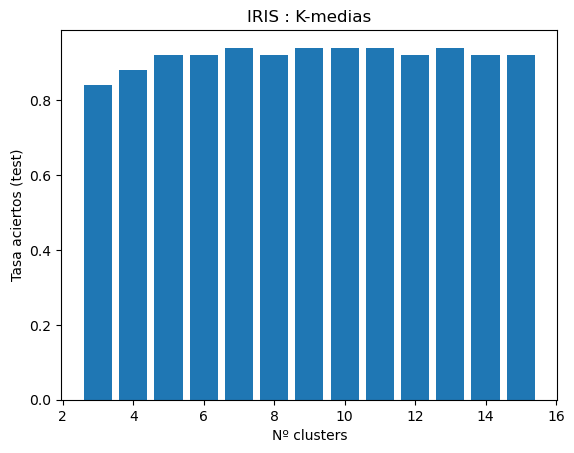

In [9]:
import matplotlib
import matplotlib.pyplot as plt
plt.bar(np.arange(min_clusters,max_clusters+1, dtype='int'), tabla.aciertos_test)
plt.title("IRIS : K-medias")
plt.xlabel("Nº clusters")
plt.ylabel("Tasa aciertos (test)")
plt.show()

In [10]:
n_optimo = tabla.index[np.argmax(tabla['aciertos_test'].to_numpy())]
print("El k óptimo es: ", n_optimo, "  con una tasa de aciertos de: ", tabla.aciertos_test.loc[n_optimo])

El k óptimo es:  7   con una tasa de aciertos de:  0.94
